# Quantum bonus, enhancement 1: Expected TD-PMD as a surface-code decoder on Google's hardware data

This notebook runs the **same cost Expected TD-PMD algorithm (SPMD + E1)** as
`gridworld_enhancement1_v12.ipynb`, on a new GridWorld: decoding a distance-3 surface code
from Google's 2022 Sycamore experiment (`surface_code_bZ_d3_r01_center_3_5`, 50,000 real shots).

| GridWorld | Decoding GridWorld |
|---|---|
| State: the cell the walker is on (100) | State: which of the 8 detectors are lit, $s\in\{0,1\}^8$ (256) |
| Action: up / right / down / left (4) | Action: flip one edge of the detector graph (23) |
| Transition: slippery move | Transition: **deterministic**, $s'=s\oplus\mathrm{mask}(a)$ |
| Cost: charged at the current cell | Cost: $c_a\propto\log\frac{1-p_a}{p_a}$; cheap = likely to have happened |
| Goal / hazard: return to origin w.p. 0.8 | Goal $s=0$ (board clear): terminal; the next episode starts from a new real syndrome |
| Randomness: the slip | Randomness: **only the start syndrome** |

**Protocol: train on half the shots, test on the other half (two folds).**

| Fold | Train | Test | Error model (costs) |
|---|---|---|---|
| A | even-index shots | odd-index shots | `pij_from_even_for_odd.dem` |
| B | odd-index shots | even-index shots | `pij_from_odd_for_even.dem` |

The training half supplies (i) the error model, which Google fitted from that half's detection
events only, and (ii) the episode start states. The test half's labels (`obs_flips_actual`) are
used only for scoring. This is the same split Google used for its belief-matching and
tensor-network decoders, so those rows are a like-for-like comparison. Across both folds, every
one of the 50,000 shots is decoded by a policy that never saw it.

**Learning** uses exactly the GridWorld E1 update: a fixed uniform behavior policy, one continuing
trajectory, $B$ transitions per round, the KL actor step, then one expected-TD critic step with
uniform weights. Exact solvers (value iteration, Bellman linear solves, exact PMD and an exact
maximum-likelihood decoder) are used **only for validation** and never enter a learning update.

Run from top to bottom. Dependencies: NumPy, pandas, Matplotlib and IPython. Stim and PyMatching
are optional; if they are installed, one extra cross-check runs. Expected runtime: about 1–3
minutes on a laptop.

> **Step 1. Settings**
>
> $$\gamma=0.9,\ \eta=0.1,\ \alpha=1,\ \vartheta=1,\ B=50,\ Q^0_{\rm cost}=\tfrac1{1-\gamma}=10.$$
>
> These are the GridWorld reference settings, except for $K$. With uniform weights $w_t=1/B$, the
> expected critic step per round for a pair is $\alpha\,d(s,a)$, where $d$ is the behavior
> visitation frequency. This does not depend on $B$. Here there are $255\times23=5{,}865$ pairs
> (the GridWorld has 400), so $d(s,a)\approx1/5{,}865$, and we need about 15× more rounds.
> We use $K=400{,}000$ rounds, which is 20,000,000 transitions per fold.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---- data -------------------------------------------------------------------------------
DATA_DIR_NAME = "smallest_google_qec3v5_experiment_data"   # searched for in the cwd and its parents
EXPERIMENT = "surface_code_bZ_d3_r01_center_3_5"

# ---- learning (GridWorld E1 reference settings, except K) --------------------------------
GAMMA = 0.9
ETA = 0.1
ALPHA = 1.0
THETA = 1.0
B = 50
N_ITERS = 400_000                 # K; N_ITERS * B = 20,000,000 transitions per fold
SEED = 0

# ---- evaluation (never used for learning) -------------------------------------------------
N_GEOM_CHECKPOINTS = 120          # log-spaced saved rounds (plus linear ones and round 0)
N_LINEAR_CHECKPOINTS = 40
EXACT_PMD_ITERS = 10_000          # exact-critic PMD reference curve
LITERAL_CHECK_ITERS = 300         # rounds replayed with the notebook's literal per-transition loop
MAX_DECODE_STEPS = 64             # cap for greedy decoding rollouts
ROLLOUT_PATHS, ROLLOUT_HORIZON = 20_000, 200

FOLDS = (
    {"name": "A", "train_parity": 0, "test_parity": 1, "dem_file": "pij_from_even_for_odd.dem"},
    {"name": "B", "train_parity": 1, "test_parity": 0, "dem_file": "pij_from_odd_for_even.dem"},
)

OUTPUT_DIR = Path(f"qec_enhancement1_B{B}_K{N_ITERS}_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert 0 <= GAMMA < 1 and ETA >= 0 and 0 < ALPHA <= 1
assert THETA == 1.0, "This experiment uses the confirmed uniform weights."

> **Step 2. Locate the experiment folder and check its inventory**
>
> The folder `smallest_google_qec3v5_experiment_data` is searched for in the working directory and
> its parents. It may contain the experiment files directly, or contain the experiment folder
> (at any depth).

In [2]:
REQUIRED_FILES = (
    "properties.yml", "circuit_ideal.stim", "circuit_detector_error_model.dem",
    "pij_from_even_for_odd.dem", "pij_from_odd_for_even.dem",
    "detection_events.b8", "obs_flips_actual.01",
    "obs_flips_predicted_by_pymatching.01", "obs_flips_predicted_by_correlated_matching.01",
    "obs_flips_predicted_by_belief_matching.01",
    "obs_flips_predicted_by_tensor_network_contraction.01",
)


def locate_experiment(data_dir_name=DATA_DIR_NAME, experiment=EXPERIMENT):
    root = None
    for base in [Path.cwd()] + list(Path.cwd().parents):
        if (base / data_dir_name).is_dir():
            root = base / data_dir_name
            break
    if root is None:
        raise FileNotFoundError(f"Could not find a folder named {data_dir_name!r} in {Path.cwd()} or its parents.")
    if (root / "detection_events.b8").is_file():
        return root
    if (root / experiment).is_dir():
        return root / experiment
    matches = sorted(p for p in root.rglob(experiment) if p.is_dir())
    if matches:
        return matches[0]
    found = sorted(p.name for p in root.iterdir())[:20]
    raise FileNotFoundError(f"{experiment!r} not found under {root}. Top-level entries: {found}")


EXP_DIR = locate_experiment()
missing = [name for name in REQUIRED_FILES if not (EXP_DIR / name).is_file()]
assert not missing, f"Missing files in {EXP_DIR}: {missing}"
print(f"Experiment folder: {EXP_DIR.resolve()}")
print("PASS: all required files are present.")

Experiment folder: /Users/jishnumahmud/Documents/codes/692_project_quantum_decoder_toric_code/smallest_google_qec3v5_experiment_data/surface_code_bZ_d3_r01_center_3_5
PASS: all required files are present.


> **Step 3. Read the shots**
>
> `properties.yml` gives the number of detectors and shots. `detection_events.b8` packs each shot's
> detector bits little-endian, so for 8 detectors the byte is the syndrome index:
>
> $$s=\sum_{i=0}^{7}2^i\,x_i .$$
>
> `obs_flips_actual.01` is the ground truth (did the logical observable flip?). It is used **only for
> scoring the test half**.

In [3]:
def read_properties(path):
    props = {}
    for line in path.read_text().splitlines():
        if ":" in line and not line.lstrip().startswith("#"):
            key, value = line.split(":", 1)
            value = value.strip()
            try:
                value = int(value)
            except ValueError:
                pass
            props[key.strip()] = value
    return props


def read_b8(path, bits_per_shot, n_shots):
    raw = np.fromfile(path, dtype=np.uint8)
    bytes_per_shot = (bits_per_shot + 7) // 8
    if raw.size != n_shots * bytes_per_shot:
        raise ValueError(f"{path.name}: {raw.size} bytes, expected {n_shots * bytes_per_shot}.")
    bits = np.unpackbits(raw.reshape(n_shots, bytes_per_shot), axis=1, bitorder="little")
    return bits[:, :bits_per_shot]


def read_01(path, n_shots):
    lines = path.read_text().split()
    if len(lines) != n_shots or set(lines) - {"0", "1"}:
        raise ValueError(f"{path.name}: expected {n_shots} lines of 0/1 (one observable).")
    return (np.array(lines) == "1").astype(np.uint8)


PROPS = read_properties(EXP_DIR / "properties.yml")
N_DET, N_SHOTS = PROPS["circuit_detectors"], PROPS["shots"]
assert PROPS["circuit_observables"] == 1
assert N_DET == 8, "This notebook is sized for the 1-round d=3 experiment (8 detectors, 256 states)."

DET_BITS = read_b8(EXP_DIR / "detection_events.b8", N_DET, N_SHOTS)
SYNDROME = (DET_BITS.astype(np.int64) << np.arange(N_DET)).sum(axis=1)
ACTUAL = read_01(EXP_DIR / "obs_flips_actual.01", N_SHOTS)
GOOGLE = {name: read_01(EXP_DIR / f"obs_flips_predicted_by_{name}.01", N_SHOTS)
          for name in ("pymatching", "correlated_matching", "belief_matching", "tensor_network_contraction")}
PARITY = np.arange(N_SHOTS) % 2
N_STATES = 1 << N_DET

assert SYNDROME.min() >= 0 and SYNDROME.max() < N_STATES
weights_hist = np.bincount(DET_BITS.sum(axis=1), minlength=N_DET + 1)
counts = np.bincount(SYNDROME, minlength=N_STATES)
display(pd.DataFrame({
    "quantity": ["basis / distance / rounds", "shots", "detectors", "states", "P(empty syndrome)",
                 "distinct syndromes seen", "syndromes never seen", "no-decoding logical error"],
    "value": [f"{PROPS['basis']} / {PROPS['distance']} / {PROPS['rounds']}", N_SHOTS, N_DET, N_STATES,
              f"{np.mean(SYNDROME == 0):.3f}", int((counts > 0).sum()), int((counts == 0).sum()),
              f"{ACTUAL.mean():.4f}"],
}))
display(pd.DataFrame({"syndrome weight": np.arange(N_DET + 1), "shots": weights_hist}).set_index("syndrome weight").T)
print("PASS: shot files have the expected sizes and formats.")

,quantity,value
0,basis / distance / rounds,Z / 3 / 1
1,shots,50000
2,detectors,8
3,states,256
4,P(empty syndrome),0.675
5,distinct syndromes seen,184
6,syndromes never seen,72
7,no-decoding logical error,0.0850


syndrome weight,0,1,2,3,4,5,6,7,8
shots,33766,6281,8145,1118,616,59,14,1,0


PASS: shot files have the expected sizes and formats.


> **Step 4. Detector error model (DEM) → edges = actions**
>
> Each `error(p) ...` line is an independent error mechanism. A `^` separates the suggested
> decomposition of a multi-detector error into graphlike pieces. Each piece touches 1 or 2
> detectors (1 = a boundary edge) and may flip the logical observable `L0`. Parallel pieces with
> the same key are XOR-merged:
>
> $$q\leftarrow q(1-p)+p(1-q).$$
>
> If the same detectors appear with both observable flags, we keep the more likely one. This is the
> rule matching decoders use. The cost of edge $a$ is its log-likelihood ratio, normalised so that
> the largest cost is 1, like the GridWorld's costs:
>
> $$c_a=\frac{\ell_a}{\max_b\ell_b},\qquad \ell_a=\log\frac{1-p_a}{p_a}.$$
>
> A positive rescaling leaves every optimal policy unchanged. With $c\le1$, every policy's cost is
> at most $1/(1-\gamma)=10$, so $Q^0=10$ is the same pessimistic initialisation as in the GridWorld.

In [4]:
def parse_dem(path):
    # Return (mechanisms, detector_coords); each mechanism is (p, ((dets, obs_parity), ...)).
    mechanisms, coords = [], {}
    for line_no, raw in enumerate(path.read_text().splitlines(), start=1):
        line = raw.split("#", 1)[0].strip()
        if not line:
            continue
        head = line.split("(", 1)[0].split()[0]
        if head == "error":
            close = line.index(")")
            p = float(line[line.index("(") + 1:close])
            pieces = [[set(), 0]]
            for token in line[close + 1:].split():
                if token == "^":
                    pieces.append([set(), 0])
                elif token.startswith("D"):
                    pieces[-1][0] ^= {int(token[1:])}
                elif token.startswith("L"):
                    if int(token[1:]) != 0:
                        raise ValueError("Only one logical observable (L0) is supported.")
                    pieces[-1][1] ^= 1
                else:
                    raise ValueError(f"{path.name}:{line_no}: unexpected target {token!r}")
            mechanisms.append((p, tuple((tuple(sorted(d)), o) for d, o in pieces)))
        elif head == "detector":
            if "(" in line:
                args = line[line.index("(") + 1:line.index(")")]
                det = int(line[line.index(")") + 1:].split()[0][1:])
                coords[det] = tuple(float(x) for x in args.split(","))
        elif head == "logical_observable":
            continue
        else:
            raise ValueError(f"{path.name}:{line_no}: unsupported DEM instruction {head!r}")
    return mechanisms, coords


def build_edges(mechanisms):
    merged = {}
    for p, pieces in mechanisms:
        for key in pieces:
            dets, _ = key
            if not 1 <= len(dets) <= 2:
                raise ValueError(f"Non-graphlike piece {key}; the DEM needs a decomposition.")
            q = merged.get(key, 0.0)
            merged[key] = q * (1 - p) + p * (1 - q)
    best, conflicts = {}, 0
    for (dets, obs), p in merged.items():
        if dets in best:
            conflicts += 1
        if dets not in best or p > best[dets][1]:
            best[dets] = (obs, p)
    items = sorted(best.items())
    edges = {
        "dets": [dets for dets, _ in items],
        "masks": np.array([sum(1 << d for d in dets) for dets, _ in items], dtype=np.int64),
        "obs": np.array([obs for _, (obs, _) in items], dtype=np.uint8),
        "p": np.array([p for _, (_, p) in items]),
        "n_mechanisms": len(mechanisms),
        "n_decomposed": sum(len(pieces) > 1 for _, pieces in mechanisms),
        "n_conflicts": conflicts,
    }
    assert np.all((edges["p"] > 0) & (edges["p"] < 0.5)), "Costs need 0 < p < 1/2."
    assert len(set(edges["masks"].tolist())) == len(items)
    return edges


DEMS = {}
for name in ("circuit_detector_error_model.dem", "pij_from_even_for_odd.dem", "pij_from_odd_for_even.dem"):
    mechanisms, coords = parse_dem(EXP_DIR / name)
    DEMS[name] = {"mechanisms": mechanisms, "coords": coords, "edges": build_edges(mechanisms)}

rows = []
for name, dem in DEMS.items():
    e = dem["edges"]
    rows.append({"DEM": name, "mechanisms": e["n_mechanisms"], "decomposed": e["n_decomposed"],
                 "edges (actions)": len(e["masks"]),
                 "boundary edges": sum(len(d) == 1 for d in e["dets"]),
                 "edges flipping L0": int(e["obs"].sum()), "obs-flag conflicts": e["n_conflicts"],
                 "p range": f"{e['p'].min():.4f}–{e['p'].max():.4f}"})
display(pd.DataFrame(rows).set_index("DEM"))

# All three models must define the same action set for this experiment.
dets_lists = [tuple(d["edges"]["dets"]) for d in DEMS.values()]
assert all(x == dets_lists[0] for x in dets_lists), "The DEMs disagree on the edge set."
obs_lists = [d["edges"]["obs"] for d in DEMS.values()]
assert all(np.array_equal(x, obs_lists[0]) for x in obs_lists), "The DEMs disagree on observable flags."
edge_table = pd.DataFrame({"detectors": [str(d) for d in dets_lists[0]],
                           "flips L0": DEMS["circuit_detector_error_model.dem"]["edges"]["obs"]})
for name, dem in DEMS.items():
    p = dem["edges"]["p"]
    llr = np.log((1 - p) / p)
    edge_table[f"p [{name.replace('.dem', '')}]"] = p.round(4)
    edge_table[f"cost [{name.replace('.dem', '')}]"] = (llr / llr.max()).round(3)
display(edge_table)
print("PASS: all three DEMs parse to the same 23 graphlike edges.")

,mechanisms,decomposed,edges (actions),boundary edges,edges flipping L0,obs-flag conflicts,p range
DEM,,,,,,,
circuit_detector_error_model.dem,29,6,23,8,4,0,0.0024–0.0661
pij_from_even_for_odd.dem,23,0,23,8,4,0,0.0028–0.0515
pij_from_odd_for_even.dem,23,0,23,8,4,0,0.0021–0.0517


,detectors,flips L0,p [circuit_detector_error_model],cost [circuit_detector_error_model],p [pij_from_even_for_odd],cost [pij_from_even_for_odd],p [pij_from_odd_for_even],cost [pij_from_odd_for_even]
0,"(0,)",1,0.0200,0.645,0.0167,0.694,0.0134,0.695
1,"(0, 2)",0,0.0099,0.763,0.0087,0.808,0.0088,0.764
2,"(0, 3)",0,0.0034,0.940,0.0059,0.874,0.0050,0.856
3,"(0, 4)",0,0.0292,0.580,0.0515,0.497,0.0517,0.470
4,"(0, 5)",0,0.0026,0.986,0.0038,0.949,0.0048,0.864
5,"(0, 7)",0,0.0092,0.775,0.0080,0.821,0.0090,0.761
6,"(1,)",1,0.0045,0.893,0.0050,0.902,0.0050,0.856
7,"(1, 3)",0,0.0040,0.914,0.0053,0.892,0.0052,0.849
8,"(1, 5)",0,0.0283,0.586,0.0270,0.611,0.0277,0.575
9,"(2,)",0,0.0134,0.712,0.0076,0.831,0.0067,0.809


PASS: all three DEMs parse to the same 23 graphlike edges.


> **The board.** Detectors are drawn at their chip coordinates. The two time layers (the measured
> round and the final data readout) are offset diagonally. Edge colour = cost (circuit DEM). Red
> outlines mark edges that flip the logical observable. Boundary edges are drawn as stubs.

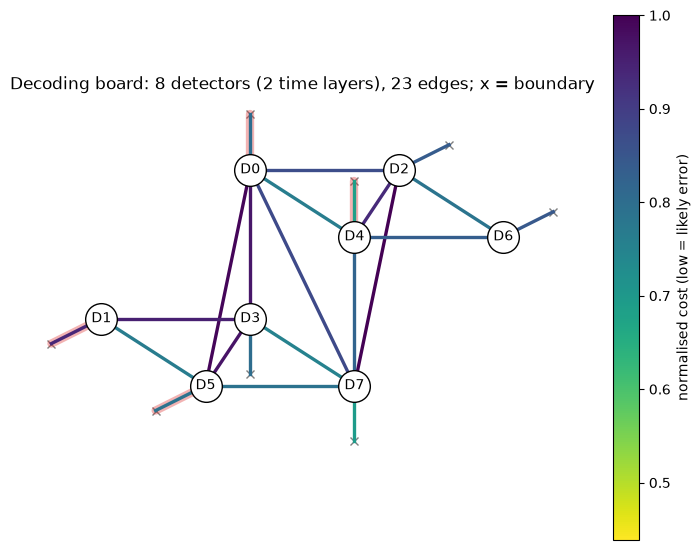

In [5]:
def plot_board(dem, title):
    coords, e = dem["coords"], dem["edges"]
    if len(coords) != N_DET:
        print("Detector coordinates unavailable; skipping the board figure.")
        return
    xy = {d: np.array([c[1] + 1.4 * c[2], -c[0] - 0.9 * c[2]]) for d, c in coords.items()}
    centre = {t: np.mean([xy[d] for d, c in coords.items() if c[2] == t], axis=0)
              for t in sorted({c[2] for c in coords.values()})}
    llr = np.log((1 - e["p"]) / e["p"])
    cost = llr / llr.max()
    cmap = plt.get_cmap("viridis_r")
    fig, ax = plt.subplots(figsize=(7.2, 5.6))
    for dets, c, o in zip(e["dets"], cost, e["obs"]):
        if len(dets) == 2:
            a, b = xy[dets[0]], xy[dets[1]]
        else:
            a = xy[dets[0]]
            direction = a - centre[coords[dets[0]][2]]
            b = a + 0.75 * direction / np.linalg.norm(direction)
            ax.plot(*b, marker="x", color="grey", ms=6)
        if o:
            ax.plot([a[0], b[0]], [a[1], b[1]], color="#dc2626", lw=6, alpha=0.35, solid_capstyle="round")
        ax.plot([a[0], b[0]], [a[1], b[1]], color=cmap(c), lw=2.4)
    for d, p in xy.items():
        ax.scatter(*p, s=520, color="white", edgecolor="black", zorder=3)
        ax.text(*p, f"D{d}", ha="center", va="center", fontsize=10, zorder=4)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(cost.min(), 1.0))
    sm.set_array([])
    fig.colorbar(sm, ax=ax, label="normalised cost (low = likely error)")
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.axis("off")
    fig.tight_layout()
    plt.show()


plot_board(DEMS["circuit_detector_error_model.dem"],
           "Decoding board: 8 detectors (2 time layers), 23 edges; x = boundary")

> **Step 5. The decoding MDP and its simulator**
>
> $$s'=s\oplus\mathrm{mask}(a),\qquad C_t=c_{A_t},\qquad s=0\ \text{terminal},\ V(0)=0.$$
>
> The simulator records the transition $(S_t,A_t,C_t,S_{t+1})$. When $S_{t+1}=0$, the board is clear
> and the simulator draws the next episode's start from the training syndromes, as the GridWorld
> returns to the origin. Empty training syndromes are skipped: they produce no transitions.
> The TD target never bootstraps through this restart, because $U(0)=0$.

In [6]:
class DecodingMDP:
    def __init__(self, edges, n_detectors=N_DET):
        self.masks = edges["masks"]
        self.obs = edges["obs"]
        self.n_states = 1 << n_detectors
        self.n_actions = len(self.masks)
        llr = np.log((1 - edges["p"]) / edges["p"])
        self.cost_scale = llr.max()
        self.cost = llr / self.cost_scale
        self.next_state = np.arange(self.n_states)[:, None] ^ self.masks[None, :]


class DecodingGridWorld:
    # One online interaction: flip one edge. When the board clears, a new training syndrome is drawn.
    def __init__(self, mdp, start_pool, rng):
        self.mdp, self.start_pool, self.rng = mdp, start_pool, rng
        self.state = self.draw_start()

    def draw_start(self):
        return int(self.start_pool[self.rng.integers(len(self.start_pool))])

    def step(self, action):
        state = self.state
        cost = self.mdp.cost[action]
        next_state = state ^ int(self.mdp.masks[action])
        done = next_state == 0
        self.state = self.draw_start() if done else next_state
        return cost, next_state, done


def check_simulator(mdp):
    class FixedStart:
        def integers(self, n):
            return 0
    for s in range(1, mdp.n_states):
        for a in range(mdp.n_actions):
            env = DecodingGridWorld(mdp, np.array([s]), FixedStart())
            cost, s2, done = env.step(a)
            assert s2 == mdp.next_state[s, a] and cost == mdp.cost[a] and done == (s2 == 0)
            assert bin(s ^ s2).count("1") == bin(int(mdp.masks[a])).count("1")


for dem in DEMS.values():
    check_simulator(DecodingMDP(dem["edges"]))
print("PASS: simulator matches the next-state table for all 255 x 23 state-action pairs.")

PASS: simulator matches the next-state table for all 255 x 23 state-action pairs.


> **Step 6. Exact tools (validation only)**
>
> $$(I-\gamma P_\pi)V^\pi=c_\pi,\qquad V^*(s)=\min_a\{c_a+\gamma V^*(s\oplus\mathrm{mask}(a))\}.$$
>
> A policy decodes a syndrome by rolling out its greedy action until the board is clear. The
> predicted logical flip is the XOR of the `L0` flags of the flipped edges. If a rollout does not
> clear the board within the step cap, the shot is counted as an error. The exact
> maximum-likelihood decoder (MLD) XOR-convolves every mechanism over the $2^9$ joint
> (syndrome, observable) outcomes and picks the likelier observable.

In [7]:
def evaluate_policy_bellman(mdp, policy, gamma):
    n = mdp.n_states
    P = np.zeros((n, n))
    P[np.arange(n)[:, None], mdp.next_state] = policy      # next states in a row are distinct
    P[0] = 0.0
    P[0, 0] = 1.0
    c = policy @ mdp.cost
    c[0] = 0.0
    values = np.linalg.solve(np.eye(n) - gamma * P, c)
    residual = np.max(np.abs(values - c - gamma * P @ values))
    if residual > 1e-10:
        raise AssertionError(f"Bellman residual too large: {residual}")
    q = mdp.cost[None, :] + gamma * values[mdp.next_state]
    q[0] = 0.0
    return values, q, residual


def value_iteration(mdp, gamma, tol=1e-13, max_iter=100_000):
    values = np.zeros(mdp.n_states)
    for _ in range(max_iter):
        q = mdp.cost[None, :] + gamma * values[mdp.next_state]
        new = q.min(axis=1)
        new[0] = 0.0
        if np.max(np.abs(new - values)) < tol:
            values = new
            break
        values = new
    q = mdp.cost[None, :] + gamma * values[mdp.next_state]
    q[0] = 0.0
    return values, q


def decode_table(mdp, greedy_actions, max_steps=MAX_DECODE_STEPS):
    # Roll out a deterministic policy from every syndrome at once.
    s = np.arange(mdp.n_states)
    prediction = np.zeros(mdp.n_states, dtype=np.uint8)
    correction = np.zeros(mdp.n_states, dtype=np.int64)       # bitmask over edges (set of flips)
    steps = np.zeros(mdp.n_states, dtype=np.int64)
    for _ in range(max_steps):
        active = s != 0
        if not active.any():
            break
        a = greedy_actions[s]
        prediction ^= (mdp.obs[a] * active).astype(np.uint8)
        correction = np.where(active, correction ^ (np.int64(1) << a), correction)
        steps += active
        s = np.where(active, s ^ mdp.masks[a], s)
    return {"prediction": prediction, "correction": correction, "steps": steps, "terminated": s == 0}


def mld_table(mechanisms, n_detectors=N_DET):
    prob = np.zeros(1 << (n_detectors + 1))
    prob[0] = 1.0
    index = np.arange(prob.size)
    for p, pieces in mechanisms:
        flip = 0
        for dets, obs in pieces:
            for d in dets:
                flip ^= 1 << d
            flip ^= obs << n_detectors
        prob = (1 - p) * prob + p * prob[index ^ flip]
    prob = prob.reshape(2, 1 << n_detectors)                  # [observable, syndrome]
    return prob.argmax(axis=0).astype(np.uint8), prob.sum(axis=0)


def logical_errors(table, shot_index):
    s = SYNDROME[shot_index]
    return (table["prediction"][s] != ACTUAL[shot_index]) | ~table["terminated"][s]


# Solver sanity checks on the circuit-DEM MDP.
_mdp = DecodingMDP(DEMS["circuit_detector_error_model.dem"]["edges"])
_uniform = np.full((_mdp.n_states, _mdp.n_actions), 1 / _mdp.n_actions)
_v0, _, _ = evaluate_policy_bellman(_mdp, _uniform, 0.0)
np.testing.assert_allclose(_v0[1:], _mdp.cost.mean())                     # gamma = 0: immediate cost
_vstar, _qstar = value_iteration(_mdp, GAMMA)
_greedy = np.eye(_mdp.n_actions)[_qstar.argmin(axis=1)]
_vg, _, _ = evaluate_policy_bellman(_mdp, _greedy, GAMMA)
np.testing.assert_allclose(_vg, _vstar, atol=1e-10)                       # greedy(Q*) attains V*
assert np.all(_vstar[_mdp.masks] <= _mdp.cost + 1e-12)                    # one flip clears mask(a)
assert np.all(_vstar[1:] > 0) and np.all(_vstar <= 1 / (1 - GAMMA))
assert decode_table(_mdp, _qstar.argmin(axis=1))["terminated"].all()
print("PASS: Bellman solver, value iteration and greedy decoding agree on known identities.")

PASS: Bellman solver, value iteration and greedy decoding agree on known identities.


> **Reference check against Google's own file.** Value iteration with likelihood costs and
> $\gamma=1$ is a minimum-weight decoder, so on the circuit DEM it should reproduce Google's
> PyMatching predictions. This tests the parser, the edge merging, the rollout and the observable
> bookkeeping in one go.

In [8]:
_, _q1 = value_iteration(_mdp, 1.0)
_tab1 = decode_table(_mdp, _q1.argmin(axis=1))
agree_pm = np.mean(_tab1["prediction"][SYNDROME] == GOOGLE["pymatching"])
print(f"Exact VI (circuit DEM, gamma=1) agrees with Google's PyMatching on {100 * agree_pm:.3f}% of the "
      f"{N_SHOTS:,} shots.")
assert agree_pm > 0.999, "DEM parsing or decoding is inconsistent with Google's PyMatching file."
print("PASS: our exact decoder reproduces Google's PyMatching predictions.")

try:
    import stim
    import pymatching
    _dets = stim.read_shot_data_file(path=str(EXP_DIR / "detection_events.b8"), format="b8",
                                     num_detectors=N_DET)
    np.testing.assert_array_equal(_dets.astype(np.uint8), DET_BITS)
    _pm = pymatching.Matching.from_detector_error_model(
        stim.DetectorErrorModel.from_file(str(EXP_DIR / "circuit_detector_error_model.dem")))
    _pred = _pm.decode_batch(_dets)[:, 0].astype(np.uint8)
    print(f"Optional: rerun PyMatching agrees with our VI on {100 * np.mean(_pred == _tab1['prediction'][SYNDROME]):.3f}% "
          f"of shots; b8 reader matches stim.")
except ImportError:
    print("Optional Stim/PyMatching cross-check skipped (not installed).")

Exact VI (circuit DEM, gamma=1) agrees with Google's PyMatching on 100.000% of the 50,000 shots.
PASS: our exact decoder reproduces Google's PyMatching predictions.
Optional Stim/PyMatching cross-check skipped (not installed).


> **Step 7. Folds and the behavior stream**
>
> The behavior policy is fixed and uniform, so the data stream does not depend on the learner. We
> therefore generate each fold's whole continuing trajectory up front: $K B$ transitions, with
> restarts from training syndromes. Within an episode the state is a running XOR, so each episode
> is one vectorised cumulative XOR. The algorithm is the one in the GridWorld notebook. Only the
> order of random draws differs, and the check below replays the stream through
> `DecodingGridWorld.step`.

In [9]:
def generate_behavior_stream(mdp, start_pool, n_transitions, rng, chunk=4096):
    masks, n_actions = mdp.masks, mdp.n_actions
    states = np.empty(n_transitions, dtype=np.int16)
    actions = np.empty(n_transitions, dtype=np.int16)
    next_states = np.empty(n_transitions, dtype=np.int16)
    draw = lambda: int(start_pool[rng.integers(len(start_pool))])
    t, s = 0, draw()
    while t < n_transitions:
        a = rng.integers(n_actions, size=chunk)
        path = s ^ np.bitwise_xor.accumulate(masks[a])        # state after each flip
        hits = np.flatnonzero(path == 0)
        length = int(hits[0]) + 1 if hits.size else chunk
        length = min(length, n_transitions - t)
        states[t] = s
        states[t + 1:t + length] = path[:length - 1]
        actions[t:t + length] = a[:length]
        next_states[t:t + length] = path[:length]
        t += length
        s = draw() if path[length - 1] == 0 else int(path[length - 1])
    return {"states": states, "actions": actions, "next_states": next_states,
            "codes": (states.astype(np.int32) * n_actions + actions).astype(np.int32),
            "dones": next_states == 0}


class ReplayStartsWorld(DecodingGridWorld):
    # The same simulator, but restarts come from a recorded list instead of a random draw.
    def __init__(self, mdp, starts):
        self.mdp, self.start_pool = mdp, None
        self._starts = iter(starts)
        self.state = self.draw_start()

    def draw_start(self):
        return next(self._starts)


def check_stream_against_simulator(mdp, stream, start_pool, n_check=50_000):
    s, a, s2, done = (stream[k][:n_check] for k in ("states", "actions", "next_states", "dones"))
    all_states = stream["states"]
    restarts = [t + 1 for t in np.flatnonzero(done) if t + 1 < len(all_states)]
    starts = [int(all_states[0])] + [int(all_states[t]) for t in restarts]
    assert np.all(np.isin(starts, start_pool)) and 0 not in starts
    env = ReplayStartsWorld(mdp, starts + [int(start_pool[0])])   # spare start for a final restart
    for t in range(n_check):
        assert env.state == s[t]
        cost, nxt, d = env.step(int(a[t]))
        assert nxt == s2[t] and d == done[t] and cost == mdp.cost[a[t]]


fold_data = {}
for fold_index, fold in enumerate(FOLDS):
    mdp = DecodingMDP(DEMS[fold["dem_file"]]["edges"])
    train = np.flatnonzero(PARITY == fold["train_parity"])
    test = np.flatnonzero(PARITY == fold["test_parity"])
    start_pool = SYNDROME[train][SYNDROME[train] != 0]
    rho = np.bincount(start_pool, minlength=N_STATES) / len(start_pool)  # episode start distribution
    started = time.perf_counter()
    stream = generate_behavior_stream(mdp, start_pool, N_ITERS * B, np.random.default_rng(SEED + fold_index))
    check_stream_against_simulator(mdp, stream, start_pool)
    fold_data[fold["name"]] = {"fold": fold, "mdp": mdp, "train": train, "test": test,
                               "start_pool": start_pool, "rho": rho, "stream": stream}
    print(f"Fold {fold['name']}: train {len(train):,} shots ({len(start_pool):,} non-empty starts), "
          f"test {len(test):,} shots; stream of {N_ITERS * B:,} transitions, "
          f"{int(stream['dones'].sum()):,} episodes ({time.perf_counter() - started:.1f}s)")
print("PASS: the vectorised stream equals a step-by-step replay through the simulator.")

Fold A: train 25,000 shots (8,119 non-empty starts), test 25,000 shots; stream of 20,000,000 transitions, 77,976 episodes (1.6s)
Fold B: train 25,000 shots (8,115 non-empty starts), test 25,000 shots; stream of 20,000,000 transitions, 78,147 episodes (1.6s)
PASS: the vectorised stream equals a step-by-step replay through the simulator.


> **Step 8. Expected TD-PMD (identical update to the GridWorld E1 notebook)**
>
> $$\pi_{k+1}(a\mid s)\propto\pi_k(a\mid s)\,e^{-\eta Q^k(s,a)},\qquad U^k(s')=\sum_b\pi_{k+1}(b\mid s')Q^k(s',b),\quad U^k(0)=0,$$
>
> $$e_t=C_t+\gamma U^k(S_{t+1})-Q^k(S_t,A_t),\qquad Q^{k+1}=Q^k+\alpha\sum_{t}w_t\mathbf 1_{\{(S_t,A_t)=(s,a)\}}e_t,\quad w_t=\tfrac1B .$$
>
> The KL step is computed in log space: $\log\pi_{k+1}=\log\pi_k-\eta Q^k$, then normalised. This is
> the same update, but over 400,000 rounds a probability could otherwise underflow to exactly 0 and
> never recover. The per-transition loop becomes one `bincount` per batch. Step 9 checks both
> changes against a literal port of the notebook's functions. History row $k$ stores
> $(\pi_k,Q^k)$, with row 0 the initialisation. Rows are saved at log-spaced checkpoints.

In [10]:
def uniform_batch_weights(batch_size):
    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")
    return np.full(batch_size, 1.0 / batch_size, dtype=float)


def softmax_rows(logits):
    z = logits - logits.max(axis=1, keepdims=True)
    p = np.exp(z)
    return p / p.sum(axis=1, keepdims=True)


def make_checkpoints(n_iters):
    geom = np.geomspace(1, n_iters, N_GEOM_CHECKPOINTS).astype(np.int64)
    lin = np.linspace(0, n_iters, N_LINEAR_CHECKPOINTS + 1).astype(np.int64)
    return np.unique(np.concatenate([[0], geom, lin]))


def run_expected_td_pmd(mdp, stream, batch_size=B, n_iters=N_ITERS, gamma=GAMMA,
                        eta=ETA, alpha=ALPHA, checkpoints=None, verbose=True, label=""):
    if not 0 <= gamma < 1 or eta < 0 or not 0 < alpha <= 1:
        raise ValueError("Require 0 <= gamma < 1, eta >= 0, and 0 < alpha <= 1.")
    if len(stream["codes"]) < n_iters * batch_size:
        raise ValueError("The behavior stream is shorter than n_iters * batch_size.")
    n_s, n_a = mdp.n_states, mdp.n_actions
    checkpoints = make_checkpoints(n_iters) if checkpoints is None else np.asarray(checkpoints)
    w = uniform_batch_weights(batch_size)[0]
    q = np.full((n_s, n_a), 1.0 / (1.0 - gamma))
    q[0] = 0.0                                                # terminal row is never updated
    logits = np.zeros((n_s, n_a))
    policy = softmax_rows(logits)

    q_hist = np.empty((len(checkpoints), n_s, n_a))
    pi_hist = np.empty_like(q_hist)
    slot = {int(k): i for i, k in enumerate(checkpoints)}
    q_hist[slot[0]], pi_hist[slot[0]] = q, policy
    codes, actions, next_states = stream["codes"], stream["actions"], stream["next_states"]
    cost = mdp.cost
    report_every = max(1, n_iters // 10)
    started = time.perf_counter()

    for k in range(n_iters):
        # Actor first: the new policy uses the previous critic.
        logits = logits - eta * q
        policy_next = softmax_rows(logits)
        expected_future = np.sum(policy_next * q, axis=1)
        expected_future[0] = 0.0
        # Critic second: one update from the next B behavior transitions (Q frozen within the batch).
        sl = slice(k * batch_size, (k + 1) * batch_size)
        code = codes[sl]
        td_error = cost[actions[sl]] + gamma * expected_future[next_states[sl]] - q.ravel()[code]
        td_sum = np.bincount(code, weights=w * td_error, minlength=n_s * n_a).reshape(n_s, n_a)
        q = q + alpha * td_sum
        policy = policy_next
        if k + 1 in slot:
            q_hist[slot[k + 1]], pi_hist[slot[k + 1]] = q, policy
        if verbose and ((k + 1) % report_every == 0):
            print(f"{label} round {k + 1:>9,}/{n_iters:,} | samples={(k + 1) * batch_size:>12,} | "
                  f"{time.perf_counter() - started:6.1f}s", flush=True)

    return {"checkpoints": checkpoints, "samples": checkpoints * batch_size,
            "q_history": q_hist, "policy_history": pi_hist,
            "v_history": np.sum(pi_hist * q_hist, axis=2),
            "final_policy": policy.copy(), "final_q": q.copy(),
            "elapsed_seconds": time.perf_counter() - started,
            "B": batch_size, "n_iters": n_iters, "gamma": gamma, "eta": eta, "alpha": alpha}

> **Step 9. Equivalence check against a literal port of the GridWorld notebook's functions**
>
> `kl_policy_update` and the per-transition TD-error loop below are copied from the GridWorld
> notebook, apart from consuming the pre-generated stream. They are run for the first
> 300 rounds on fold A's stream. Every round's $\pi$ and $Q$ must match the vectorised
> implementation.

In [11]:
def kl_policy_update(policy, q_values, eta):
    # Verbatim from the GridWorld notebook (probability space).
    if eta < 0:
        raise ValueError("eta must be nonnegative.")
    if eta == 0:
        return policy.copy()
    scores = -eta * q_values
    scores -= scores.max(axis=1, keepdims=True)
    weights = policy * np.exp(scores)
    return weights / weights.sum(axis=1, keepdims=True)


def literal_expected_td_pmd(mdp, stream, batch_size, n_iters, gamma, eta, alpha):
    policy = np.full((mdp.n_states, mdp.n_actions), 1.0 / mdp.n_actions)
    q = np.full((mdp.n_states, mdp.n_actions), 1.0 / (1.0 - gamma))
    q[0] = 0.0
    weights = uniform_batch_weights(batch_size)
    q_hist, pi_hist = [q], [policy]
    t = 0
    for k in range(n_iters):
        policy_next = kl_policy_update(policy, q, eta)
        expected_future = np.sum(policy_next * q, axis=1)     # U(0) = 0 because Q(0, .) = 0
        td_sum = np.zeros_like(q)
        for weight in weights:
            state, action = int(stream["states"][t]), int(stream["actions"][t])
            cost, next_state = mdp.cost[action], int(stream["next_states"][t])
            td_target = cost + gamma * expected_future[next_state]
            td_sum[state, action] += weight * (td_target - q[state, action])
            t += 1
        q = q + alpha * td_sum
        policy = policy_next
        q_hist.append(q)
        pi_hist.append(policy)
    return np.array(q_hist), np.array(pi_hist)


_fd = fold_data["A"]
_lit_q, _lit_pi = literal_expected_td_pmd(_fd["mdp"], _fd["stream"], B, LITERAL_CHECK_ITERS, GAMMA, ETA, ALPHA)
_vec = run_expected_td_pmd(_fd["mdp"], _fd["stream"], n_iters=LITERAL_CHECK_ITERS,
                           checkpoints=np.arange(LITERAL_CHECK_ITERS + 1), verbose=False)
np.testing.assert_allclose(_vec["q_history"], _lit_q, atol=1e-12, rtol=0)
np.testing.assert_allclose(_vec["policy_history"], _lit_pi, atol=1e-12, rtol=0)
_changed = np.any(_lit_q[1:] != _lit_q[:-1], axis=0)
print(f"Literal port and vectorised implementation agree on all {LITERAL_CHECK_ITERS} rounds "
      f"({int(_changed.sum())} pairs updated at least once).")
print("PASS: vectorised Expected TD-PMD is the GridWorld notebook's algorithm.")

Literal port and vectorised implementation agree on all 300 rounds (5375 pairs updated at least once).
PASS: vectorised Expected TD-PMD is the GridWorld notebook's algorithm.


> **Step 10. Train both folds**
>
> The training uses only the behavior stream: no transition matrix, Bellman solution or test label
> enters an update.

In [12]:
runs = {}
for name, fd in fold_data.items():
    runs[name] = run_expected_td_pmd(fd["mdp"], fd["stream"], label=f"fold {name} |")
    run = runs[name]
    assert np.isfinite(run["q_history"]).all()
    assert run["q_history"].min() >= -1e-10 and run["q_history"].max() <= 1 / (1 - GAMMA) + 1e-10
    assert np.all(run["q_history"][:, 0, :] == 0.0)
    np.testing.assert_allclose(run["policy_history"].sum(axis=2), 1.0, atol=1e-12)
    print(f"Fold {name}: finished in {run['elapsed_seconds']:.1f}s")
print("PASS: histories are finite, bounded in [0, 1/(1-gamma)], normalised, and the terminal row is untouched.")

fold A | round    40,000/400,000 | samples=   2,000,000 |    1.2s
fold A | round    80,000/400,000 | samples=   4,000,000 |    2.4s
fold A | round   120,000/400,000 | samples=   6,000,000 |    3.6s
fold A | round   160,000/400,000 | samples=   8,000,000 |    4.7s
fold A | round   200,000/400,000 | samples=  10,000,000 |    5.9s
fold A | round   240,000/400,000 | samples=  12,000,000 |    7.1s
fold A | round   280,000/400,000 | samples=  14,000,000 |    8.2s
fold A | round   320,000/400,000 | samples=  16,000,000 |    9.4s
fold A | round   360,000/400,000 | samples=  18,000,000 |   10.5s
fold A | round   400,000/400,000 | samples=  20,000,000 |   11.7s
Fold A: finished in 11.7s
fold B | round    40,000/400,000 | samples=   2,000,000 |    1.3s
fold B | round    80,000/400,000 | samples=   4,000,000 |    2.6s
fold B | round   120,000/400,000 | samples=   6,000,000 |    3.8s
fold B | round   160,000/400,000 | samples=   8,000,000 |    4.9s
fold B | round   200,000/400,000 | samples=  10,00

> **Step 11. Evaluate every saved policy after training**
>
> For each checkpoint we report:
> - **Objective.** $J(\pi)=\sum_s\rho(s)V^\pi(s)$, where $\rho$ is the episode start distribution
>   (the non-empty training syndromes). This is the analogue of $V^\pi(0)$ in the GridWorld.
>   Alongside it, the critic's $\widehat J=\sum_s\rho(s)\sum_a\pi(a\mid s)Q(s,a)$ and the optimum $J^*$.
> - **Value gaps.** $\max_s|V^{\pi_k}(s)-V^*(s)|$, and the critic error
>   $\max_s|\widehat V_k(s)-V^{\pi_k}(s)|$.
> - **Decoding.** The test-half logical error of the greedy policy $\arg\max_a\pi_k(a\mid s)$, and the
>   number of syndromes where its set of flips matches that of the exact optimum (same costs, same
>   $\gamma$).
> - **Coverage.** States and state–action pairs the behavior stream has visited so far.

In [13]:
evals = {}
for name, fd in fold_data.items():
    mdp, run, rho, test = fd["mdp"], runs[name], fd["rho"], fd["test"]
    v_star, q_star = value_iteration(mdp, GAMMA)
    opt_table = decode_table(mdp, q_star.argmin(axis=1))
    n_ck = len(run["checkpoints"])
    out = {k: np.empty(n_ck) for k in ("J_bellman", "J_critic", "max_gap", "critic_max_err",
                                       "critic_rho_err", "test_error", "same_correction",
                                       "same_prediction", "nonterminating")}
    v_bellman = np.empty((n_ck, mdp.n_states))
    for i, (pi, v_hat) in enumerate(zip(run["policy_history"], run["v_history"])):
        v, _, _ = evaluate_policy_bellman(mdp, pi, GAMMA)
        v_bellman[i] = v
        table = decode_table(mdp, pi.argmax(axis=1))
        out["J_bellman"][i] = rho @ v
        out["J_critic"][i] = rho @ v_hat
        out["max_gap"][i] = np.max(np.abs(v - v_star))
        out["critic_max_err"][i] = np.max(np.abs(v_hat - v))
        out["critic_rho_err"][i] = rho @ np.abs(v_hat - v)
        out["test_error"][i] = logical_errors(table, test).mean()
        out["same_correction"][i] = np.sum(table["correction"] == opt_table["correction"])
        out["same_prediction"][i] = np.sum((table["prediction"] == opt_table["prediction"]) & table["terminated"])
        out["nonterminating"][i] = np.sum(~table["terminated"])
    # Coverage from first-visit times in the stream.
    stream = fd["stream"]
    first_pair = np.full(mdp.n_states * mdp.n_actions, np.iinfo(np.int64).max)
    uniq, idx = np.unique(stream["codes"], return_index=True)
    first_pair[uniq] = idx
    first_state = np.full(mdp.n_states, np.iinfo(np.int64).max)
    uniq_s, idx_s = np.unique(stream["states"], return_index=True)
    first_state[uniq_s] = idx_s
    out["states_ever"] = np.array([np.sum(first_state < n) for n in run["samples"]])
    out["pairs_ever"] = np.array([np.sum(first_pair < n) for n in run["samples"]])
    out.update({"v_star": v_star, "q_star": q_star, "J_star": rho @ v_star, "v_bellman": v_bellman,
                "opt_table": opt_table,
                "final_visits": np.bincount(stream["codes"][:N_ITERS * B], minlength=mdp.n_states * mdp.n_actions)})
    evals[name] = out
    final_v = v_bellman[-1]
    final_table = decode_table(mdp, run["final_policy"].argmax(axis=1))
    gap_states = (final_v - v_star) > 1e-3
    diff_flips = final_table["correction"] != opt_table["correction"]
    out["gap_states"], out["diff_flips"] = gap_states, diff_flips

    final = {k: out[k][-1] for k in ("J_bellman", "max_gap", "critic_max_err", "test_error",
                                     "same_correction", "same_prediction")}
    visits = out["final_visits"].reshape(mdp.n_states, mdp.n_actions)[1:]
    print(f"Fold {name}: J* = {out['J_star']:.5f}, final J = {final['J_bellman']:.5f}, "
          f"max|V-V*| = {final['max_gap']:.4f}, critic max err = {final['critic_max_err']:.2e}, "
          f"test error = {final['test_error']:.4f} (optimum {logical_errors(opt_table, test).mean():.4f}); "
          f"same flips as optimum on {int(final['same_correction'])}/256 syndromes, same prediction on "
          f"{int(final['same_prediction'])}/256; visits per pair min/median = {visits.min()}/{int(np.median(visits))}")
    print(f"        states with V-V* > 1e-3: {int(gap_states.sum())}, of which {int((gap_states & ~diff_flips).sum())} "
          f"use the optimum's flips in another order; syndromes with different flips: {int(diff_flips.sum())}, "
          f"covering {np.isin(SYNDROME, np.flatnonzero(diff_flips)).mean():.5f} of all shots")

Fold A: J* = 0.71685, final J = 0.71762, max|V-V*| = 0.1219, critic max err = 7.84e-03, test error = 0.0157 (optimum 0.0157); same flips as optimum on 240/256 syndromes, same prediction on 248/256; visits per pair min/median = 3110/3409
        states with V-V* > 1e-3: 79, of which 63 use the optimum's flips in another order; syndromes with different flips: 16, covering 0.00134 of all shots
Fold B: J* = 0.67555, final J = 0.67602, max|V-V*| = 0.0642, critic max err = 6.55e-03, test error = 0.0171 (optimum 0.0171); same flips as optimum on 250/256 syndromes, same prediction on 254/256; visits per pair min/median = 3156/3411
        states with V-V* > 1e-3: 73, of which 67 use the optimum's flips in another order; syndromes with different flips: 6, covering 0.00012 of all shots


> **Exact-critic reference: exact PMD with the same $\eta$**
>
> $$\pi_{k+1}(a\mid s)\propto\pi_k(a\mid s)\,e^{-\eta Q^{\pi_k}(s,a)},\qquad Q^{\pi_k}\ \text{from the Bellman solve.}$$
>
> This is the same actor, given a perfect critic. Comparing it with Expected TD-PMD round by round
> isolates the cost of estimating $Q$ from samples.

In [14]:
exact_pmd = {}
for name, fd in fold_data.items():
    mdp, rho, v_star = fd["mdp"], fd["rho"], evals[name]["v_star"]
    logits = np.zeros((mdp.n_states, mdp.n_actions))
    max_gap, j_gap = np.empty(EXACT_PMD_ITERS + 1), np.empty(EXACT_PMD_ITERS + 1)
    started = time.perf_counter()
    for k in range(EXACT_PMD_ITERS + 1):
        pi = softmax_rows(logits)
        v, q, _ = evaluate_policy_bellman(mdp, pi, GAMMA)
        max_gap[k], j_gap[k] = np.max(np.abs(v - v_star)), rho @ (v - v_star)
        logits = logits - ETA * q
    exact_pmd[name] = {"max_gap": max_gap, "J_gap": j_gap}
    hits = {thr: int(np.argmax(max_gap < thr)) if np.any(max_gap < thr) else None for thr in (1e-1, 1e-2, 1e-3)}
    print(f"Fold {name}: exact PMD rounds to max|V-V*| < 0.1 / 0.01 / 0.001: "
          f"{hits[1e-1]} / {hits[1e-2]} / {hits[1e-3]}  ({time.perf_counter() - started:.1f}s)")

Fold A: exact PMD rounds to max|V-V*| < 0.1 / 0.01 / 0.001: 151 / 1462 / 8888  (3.2s)
Fold B: exact PMD rounds to max|V-V*| < 0.1 / 0.01 / 0.001: 137 / 1159 / 6358  (3.2s)


> **Cross-check the Bellman values with separate rollouts**
>
> We freeze three of fold A's saved policies (uniform at round 0, mid-training, final) and simulate
> 20,000 independent 200-step paths from two start states: the most common training syndrome and
> the rarest one. The average discounted
> cost must match the Bellman value, up to sampling error plus the omitted tail
> $\gamma^H/(1-\gamma)$. The final policy is almost deterministic, so its standard error is near 0.
> The earlier policies test the stochastic averaging. This is validation only.

In [15]:
def rollout_value_check(mdp, policy, start, gamma, seed, n_paths=ROLLOUT_PATHS, horizon=ROLLOUT_HORIZON):
    rng = np.random.default_rng(seed)
    s = np.full(n_paths, start, dtype=np.int64)
    returns = np.zeros(n_paths)
    cdf = policy.cumsum(axis=1)
    cdf[:, -1] = 1.0
    for t in range(horizon):
        active = s != 0
        a = (rng.random(n_paths)[:, None] > cdf[s]).sum(axis=1)
        returns += np.where(active, gamma ** t * mdp.cost[a], 0.0)
        s = np.where(active, s ^ mdp.masks[a], 0)
    return returns.mean(), returns.std(ddof=1) / np.sqrt(n_paths), gamma ** horizon / (1 - gamma)


fd, ev, run = fold_data["A"], evals["A"], runs["A"]
pool_counts = np.bincount(fd["start_pool"], minlength=N_STATES)
seen = np.flatnonzero(pool_counts)
starts = [int(np.argmax(pool_counts)), int(seen[np.argmin(pool_counts[seen])])]   # most common, rarest
mid = int(np.argmax(run["samples"] >= 100_000))
rows = []
for i in (0, mid, len(run["checkpoints"]) - 1):                 # uniform, mid-training, final policy
    for j, s0 in enumerate(starts):
        mean, se, tail = rollout_value_check(fd["mdp"], run["policy_history"][i], s0, GAMMA, 20261121 + 10 * i + j)
        exact = ev["v_bellman"][i, s0]
        assert abs(mean - exact) <= 6 * se + tail, (i, s0, mean, exact, se)
        rows.append({"round": int(run["checkpoints"][i]), "start syndrome": s0,
                     "training count": int(pool_counts[s0]), "bellman V": exact, "rollout mean": mean,
                     "standard error": se, "V*": ev["v_star"][s0]})
display(pd.DataFrame(rows).round(6))
print("PASS: rollouts agree with the Bellman values within sampling uncertainty.")

,round,start syndrome,training count,bellman V,rollout mean,standard error,V*
0,0,16,940,6.898745,6.914290,0.012803,0.511055
1,0,7,1,7.323358,7.324680,0.006221,1.619957
2,2199,16,940,0.511055,0.511055,0.000000,0.511055
3,2199,7,1,1.619957,1.619957,0.000000,1.619957
4,400000,16,940,0.511055,0.511055,0.000000,0.511055
5,400000,7,1,1.629364,1.629364,0.000000,1.619957


PASS: rollouts agree with the Bellman values within sampling uncertainty.


> **Step 12. Logical error on the real test shots**
>
> Each fold is decoded with its own training-half error model. The *all 50,000* column pools the
> two test halves, so every shot is predicted by a model that did not see it. Google's belief
> matching and tensor-network rows used the same even/odd split. Its PyMatching and correlated
> matching rows used the circuit DEM. Standard errors are binomial.

In [16]:
def summarise(pred_by_fold):
    row = {}
    total_err, total_n = 0, 0
    for name, fd in fold_data.items():
        err = pred_by_fold[name]
        row[f"fold {name} (test {('odd' if fd['fold']['test_parity'] else 'even')})"] = err.mean()
        total_err += err.sum()
        total_n += len(err)
    rate = total_err / total_n
    row["all 50,000"] = rate
    row["± s.e."] = np.sqrt(rate * (1 - rate) / total_n)
    row["errors"] = int(total_err)
    return row


decoders = {}
decoders["No decoding"] = {n: ACTUAL[fd["test"]] == 1 for n, fd in fold_data.items()}
for label, key in [("Google: PyMatching (circuit DEM)", "pymatching"),
                   ("Google: correlated matching (circuit DEM)", "correlated_matching"),
                   ("Google: belief matching (pij, same split)", "belief_matching"),
                   ("Google: tensor network (pij, same split)", "tensor_network_contraction")]:
    decoders[label] = {n: GOOGLE[key][fd["test"]] != ACTUAL[fd["test"]] for n, fd in fold_data.items()}
for label, gamma in [("Exact VI, gamma=1 (pij) = min-weight", 1.0), ("Exact VI, gamma=0.9 (pij) = RL target", GAMMA)]:
    decoders[label] = {}
    for n, fd in fold_data.items():
        _, q = value_iteration(fd["mdp"], gamma)
        decoders[label][n] = logical_errors(decode_table(fd["mdp"], q.argmin(axis=1)), fd["test"])
decoders["Exact MLD (pij)"] = {}
for n, fd in fold_data.items():
    table, _ = mld_table(DEMS[fd["fold"]["dem_file"]]["mechanisms"])
    decoders["Exact MLD (pij)"][n] = table[SYNDROME[fd["test"]]] != ACTUAL[fd["test"]]
decoders["Expected TD-PMD (SPMD + E1), final policy"] = {
    n: logical_errors(decode_table(fd["mdp"], runs[n]["final_policy"].argmax(axis=1)), fd["test"])
    for n, fd in fold_data.items()}

results = pd.DataFrame({label: summarise(v) for label, v in decoders.items()}).T
results["errors"] = results["errors"].astype(int)
display(results.round(4))

# Paired comparison with the exact optimum the learner is chasing.
td = np.concatenate([decoders["Expected TD-PMD (SPMD + E1), final policy"][n] for n in fold_data])
vi = np.concatenate([decoders["Exact VI, gamma=0.9 (pij) = RL target"][n] for n in fold_data])
pm = np.concatenate([decoders["Google: PyMatching (circuit DEM)"][n] for n in fold_data])
print(f"TD-PMD vs exact optimum: TD wrong & optimum right = {int(np.sum(td & ~vi))}, "
      f"TD right & optimum wrong = {int(np.sum(~td & vi))} (of {len(td):,} shots).")
print(f"TD-PMD vs Google PyMatching: TD wrong & PM right = {int(np.sum(td & ~pm))}, "
      f"TD right & PM wrong = {int(np.sum(~td & pm))}.")

,fold A (test odd),fold B (test even),"all 50,000",± s.e.,errors
No decoding,0.0832,0.0868,0.0850,0.0012,4250
Google: PyMatching (circuit DEM),0.0158,0.0170,0.0164,0.0006,819
Google: correlated matching (circuit DEM),0.0158,0.0170,0.0164,0.0006,819
"Google: belief matching (pij, same split)",0.0157,0.0171,0.0164,0.0006,821
"Google: tensor network (pij, same split)",0.0156,0.0172,0.0164,0.0006,819
"Exact VI, gamma=1 (pij) = min-weight",0.0157,0.0171,0.0164,0.0006,821
"Exact VI, gamma=0.9 (pij) = RL target",0.0157,0.0171,0.0164,0.0006,821
Exact MLD (pij),0.0156,0.0172,0.0164,0.0006,819
"Expected TD-PMD (SPMD + E1), final policy",0.0157,0.0171,0.0164,0.0006,821


TD-PMD vs exact optimum: TD wrong & optimum right = 11, TD right & optimum wrong = 11 (of 50,000 shots).
TD-PMD vs Google PyMatching: TD wrong & PM right = 16, TD right & PM wrong = 14.


> **Step 13. Figures**
>
> All curves come from saved policies. The $x$-axes are logarithmic because most of the change
> happens early.

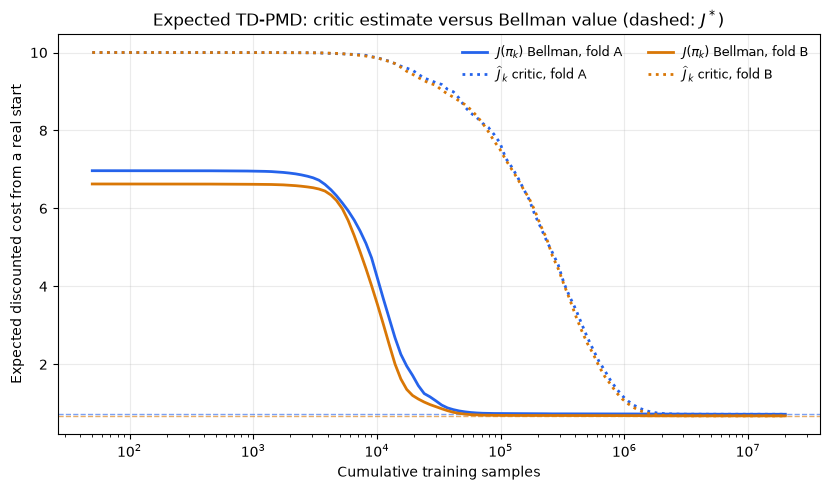

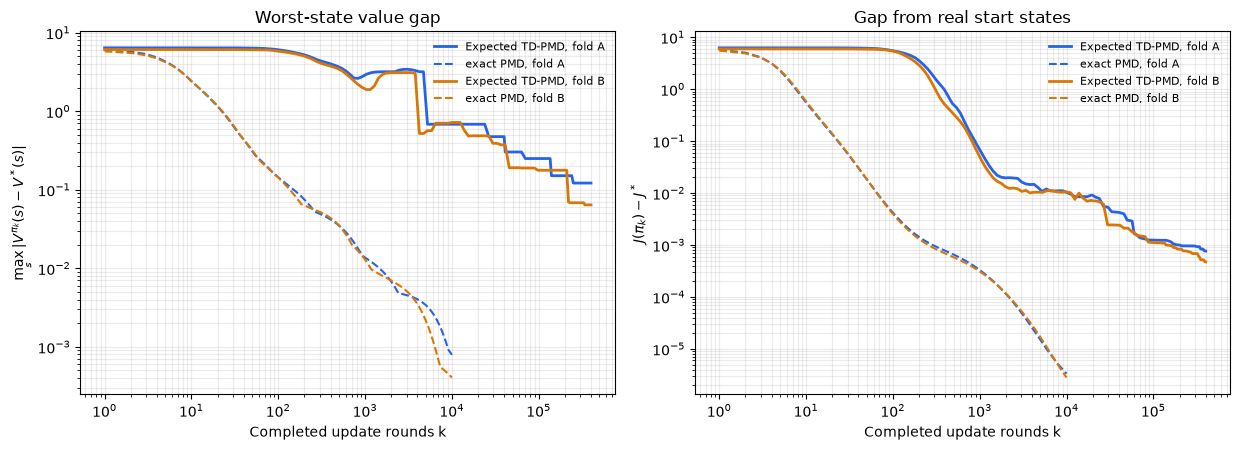

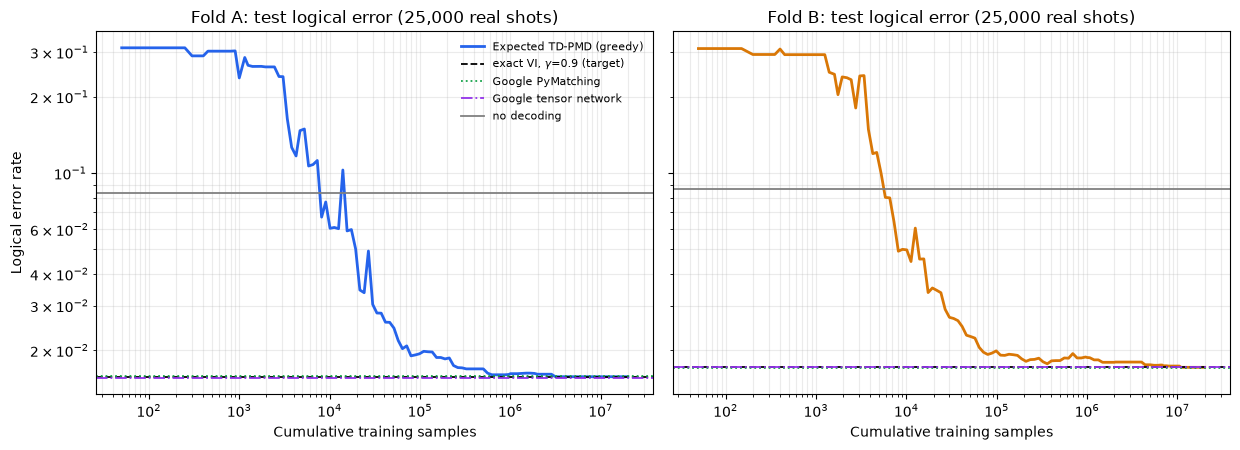

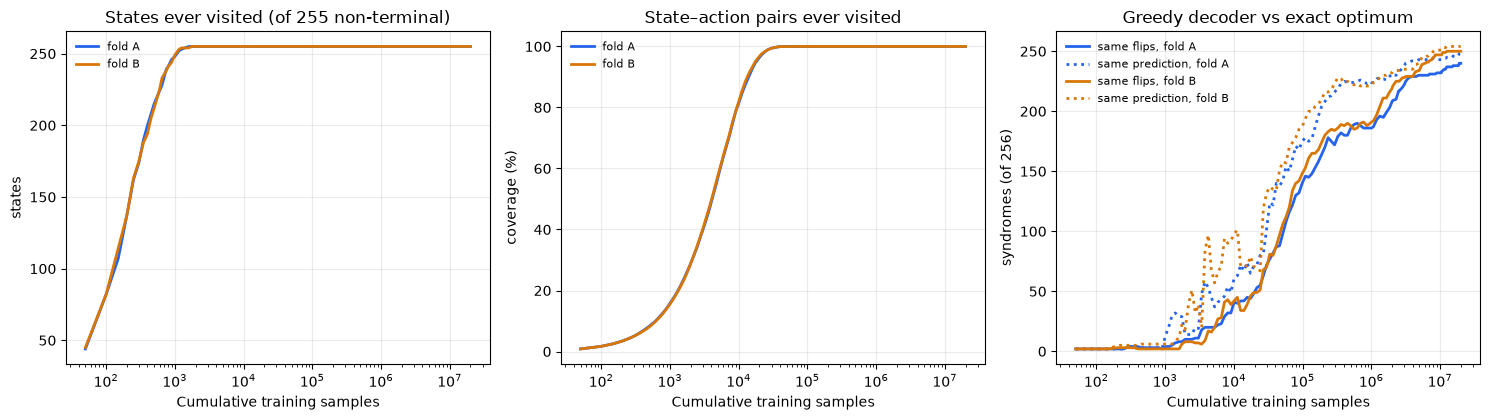

In [17]:
FOLD_COLORS = {"A": "#2563eb", "B": "#d97706"}

# Figure 1: objective, Bellman versus critic (analogue of the GridWorld V(0) figure).
fig, ax = plt.subplots(figsize=(8.4, 5.0))
for name in fold_data:
    x, ev = runs[name]["samples"][1:], evals[name]
    ax.plot(x, ev["J_bellman"][1:], "-", color=FOLD_COLORS[name], lw=2, label=f"$J(\\pi_k)$ Bellman, fold {name}")
    ax.plot(x, ev["J_critic"][1:], ":", color=FOLD_COLORS[name], lw=2, label=f"$\\widehat J_k$ critic, fold {name}")
    ax.axhline(ev["J_star"], color=FOLD_COLORS[name], lw=1, ls="--", alpha=0.6)
ax.set(xscale="log", xlabel="Cumulative training samples", ylabel="Expected discounted cost from a real start",
       title="Expected TD-PMD: critic estimate versus Bellman value (dashed: $J^*$)")
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=9, ncol=2)
fig.tight_layout()
plt.show()

# Figure 2: value gaps against update rounds, with the exact-critic reference.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for name in fold_data:
    k, ev = runs[name]["checkpoints"][1:], evals[name]
    axes[0].plot(k, ev["max_gap"][1:], color=FOLD_COLORS[name], lw=2, label=f"Expected TD-PMD, fold {name}")
    axes[1].plot(k, ev["J_bellman"][1:] - ev["J_star"], color=FOLD_COLORS[name], lw=2, label=f"Expected TD-PMD, fold {name}")
    kk = np.arange(1, EXACT_PMD_ITERS + 1)
    axes[0].plot(kk, exact_pmd[name]["max_gap"][1:], "--", color=FOLD_COLORS[name], lw=1.5, label=f"exact PMD, fold {name}")
    axes[1].plot(kk, exact_pmd[name]["J_gap"][1:], "--", color=FOLD_COLORS[name], lw=1.5, label=f"exact PMD, fold {name}")
axes[0].set(ylabel=r"$\max_s |V^{\pi_k}(s)-V^*(s)|$", title="Worst-state value gap")
axes[1].set(ylabel=r"$J(\pi_k)-J^*$", title="Gap from real start states")
for ax in axes:
    ax.set(xscale="log", yscale="log", xlabel="Completed update rounds k")
    ax.grid(alpha=0.25, which="both")
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

# Figure 3: test logical error of the greedy policy.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
for ax, name in zip(axes, fold_data):
    x, ev = runs[name]["samples"][1:], evals[name]
    ax.plot(x, ev["test_error"][1:], color=FOLD_COLORS[name], lw=2, label="Expected TD-PMD (greedy)")
    refs = {"exact VI, $\\gamma$=0.9 (target)": ("Exact VI, gamma=0.9 (pij) = RL target", "black", "--"),
            "Google PyMatching": ("Google: PyMatching (circuit DEM)", "#16a34a", ":"),
            "Google tensor network": ("Google: tensor network (pij, same split)", "#9333ea", "-."),
            "no decoding": ("No decoding", "grey", "-")}
    for lab, (key, col, ls) in refs.items():
        ax.axhline(decoders[key][name].mean(), color=col, ls=ls, lw=1.3, label=lab)
    ax.set(xscale="log", yscale="log", xlabel="Cumulative training samples",
           title=f"Fold {name}: test logical error ({len(fold_data[name]['test']):,} real shots)")
    ax.grid(alpha=0.25, which="both")
axes[0].set_ylabel("Logical error rate")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

# Figure 4: coverage and agreement with the optimal decoder.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for name in fold_data:
    x, ev = runs[name]["samples"][1:], evals[name]
    axes[0].plot(x, ev["states_ever"][1:], color=FOLD_COLORS[name], lw=2, label=f"fold {name}")
    axes[1].plot(x, 100 * ev["pairs_ever"][1:] / (255 * fold_data[name]["mdp"].n_actions),
                 color=FOLD_COLORS[name], lw=2, label=f"fold {name}")
    axes[2].plot(x, ev["same_correction"][1:], color=FOLD_COLORS[name], lw=2, label=f"same flips, fold {name}")
    axes[2].plot(x, ev["same_prediction"][1:], ":", color=FOLD_COLORS[name], lw=2, label=f"same prediction, fold {name}")
axes[0].set(title="States ever visited (of 255 non-terminal)", ylabel="states")
axes[1].set(title="State–action pairs ever visited", ylabel="coverage (%)")
axes[2].set(title="Greedy decoder vs exact optimum", ylabel="syndromes (of 256)")
for ax in axes:
    ax.set(xscale="log", xlabel="Cumulative training samples")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

> **Step 14. Save all learning and evaluation arrays**

In [18]:
arrays = {"gamma": GAMMA, "eta": ETA, "alpha": ALPHA, "theta": THETA, "B": B, "n_iters": N_ITERS, "seed": SEED,
          "experiment": EXPERIMENT, "syndrome": SYNDROME, "actual": ACTUAL}
for name, fd in fold_data.items():
    run, ev, p = runs[name], evals[name], f"fold{name}_"
    arrays.update({
        p + "dem_file": fd["fold"]["dem_file"], p + "train_index": fd["train"], p + "test_index": fd["test"],
        p + "edge_masks": fd["mdp"].masks, p + "edge_obs": fd["mdp"].obs, p + "edge_cost": fd["mdp"].cost,
        p + "cost_scale": fd["mdp"].cost_scale, p + "rho": fd["rho"],
        p + "checkpoints": run["checkpoints"], p + "samples": run["samples"],
        p + "Q_history": run["q_history"], p + "policy_history": run["policy_history"],
        p + "V_critic_history": run["v_history"], p + "V_bellman_history": ev["v_bellman"],
        p + "V_star": ev["v_star"], p + "Q_star": ev["q_star"], p + "J_star": ev["J_star"],
        p + "exact_pmd_max_gap": exact_pmd[name]["max_gap"], p + "exact_pmd_J_gap": exact_pmd[name]["J_gap"],
        p + "final_pair_visits": ev["final_visits"],
    })
    for key in ("J_bellman", "J_critic", "max_gap", "critic_max_err", "critic_rho_err", "test_error",
                "same_correction", "same_prediction", "nonterminating", "states_ever", "pairs_ever"):
        arrays[p + key] = ev[key]
arrays["results_index"] = np.array(results.index, dtype=str)
arrays["results_columns"] = np.array(results.columns, dtype=str)
arrays["results_values"] = results.to_numpy(dtype=float)

results_path = OUTPUT_DIR / f"qec_enhancement1_B{B}_K{N_ITERS}_results.npz"
np.savez_compressed(results_path, **arrays)
results.to_csv(OUTPUT_DIR / "logical_error_table.csv")
with np.load(results_path, allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved["foldA_policy_history"], runs["A"]["policy_history"])
    np.testing.assert_array_equal(saved["foldB_V_bellman_history"], evals["B"]["v_bellman"])
print(f"Saved {results_path} and {OUTPUT_DIR / 'logical_error_table.csv'}")

Saved qec_enhancement1_B50_K400000_outputs/qec_enhancement1_B50_K400000_results.npz and qec_enhancement1_B50_K400000_outputs/logical_error_table.csv


**Reading the results**

- **Decoding quality converges long before the values do.** The test logical error depends only
  on the *set* of flips the greedy policy makes. With $\gamma<1$, the optimum also prefers the
  cheapest flip *first*, so different orders of the same flips have slightly different values. Most
  states that still have a value gap use the optimum's flips in another order. The worst-state gap
  $\max_s|V^{\pi_k}-V^*|$ sits at a few syndromes with genuinely different flips. These are very
  rare in the data (Step 11 prints how rare). "Same flips" and "same prediction" in Figure 4 measure
  what decoding cares about.
- **The actor improves before the critic is accurate (Figure 1).** The critic's $\widehat J$ stays
  near its initial 10 for the first ~$10^4$ samples, while $J(\pi_k)$ is already falling. The KL step
  only uses *differences* in $Q$ across actions, and those become informative before the absolute
  level does.
- **Expected TD-PMD versus exact PMD (Figure 2).** Both use the same actor. Exact PMD is the
  limit with a perfect critic. The gap between them is the cost of learning $Q$ from samples. Early
  on, the pessimistic $Q^0=10$ and the small per-visit step $\alpha/B$ make the policy favour
  whichever actions happen to be visited first. Because the KL step remembers every past $Q$, these
  early preferences take many rounds to undo where the true difference is small.
- **Data use.** The training half supplies the error model (costs) and the start states. Under the
  uniform behavior policy, the states visited depend little on where episodes start, so the costs
  carry most of the data's influence. The test half is used only for scoring.

History rows: `foldX_Q_history`, `foldX_policy_history` and `foldX_V_bellman_history` have one row per
saved round in `foldX_checkpoints` (row 0 = initialisation). Samples are `foldX_samples` = round × B.
Load with `np.load(results_path, allow_pickle=False)`.